# Sea-breeze identification on WRF output

This notebook is a WRF-specific adaptation of the ERA5 sea-breeze example. It keeps only the moisture frontogenesis workflow.

What this notebook does:
- loads one WRF snapshot
- extracts `U10`, `V10`, `Q2`
- computes specific humidity from `Q2` using `q = r / (1 + r)`
- subsets the requested lat/lon window and LU_INDEX mask (for urban areas)
- calls `sea_breeze_funcs.kinematic_frontogenesis(q, u, v)`
- plots the result
- extends the analysis to a multi-experiment set

Assumptions made explicit:
- `Q2` is already in kg/kg.
- The `sea_breeze` code is cloned locally into this directory.
- The sea-breeze diagnostic needed here is only kinematic moisture frontogenesis.

## Installation

In [43]:
import subprocess
import sys
from pathlib import Path

sea_breeze_dir = Path('sea_breeze')

if not sea_breeze_dir.exists():
    print('Cloning sea_breeze repository...')
    subprocess.run(['git', 'clone', 'https://github.com/andrewbrown31/sea_breeze.git', str(sea_breeze_dir)], check=True)
    print('sea_breeze cloned successfully.')
else:
    print('sea_breeze directory already exists.')

# Add to sys.path so we can import it
if str(sea_breeze_dir.resolve()) not in sys.path:
    sys.path.insert(0, str(sea_breeze_dir.resolve()))

# Install remaining dependencies (sea_breeze itself has dependencies)
print('Installing sea_breeze dependencies...')
subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet', 'xarray', 'netCDF4', 'matplotlib', 'dask', 'scipy', 'scikit-image', 'metpy'], check=False)

sea_breeze directory already exists.
Installing sea_breeze dependencies...


CompletedProcess(args=['c:\\Users\\z5493395\\AppData\\Local\\anaconda3\\python.exe', '-m', 'pip', 'install', '--quiet', 'xarray', 'netCDF4', 'matplotlib', 'dask', 'scipy', 'scikit-image', 'metpy'], returncode=0)

In [96]:
from sea_breeze import (
load_model_data,
sea_breeze_funcs,
sea_breeze_filters
)

## Configuration
For WRF snapshot of 2017-01-17 05:00 UTC, which is 15:00 AEST.

In [125]:
from pathlib import Path

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
import sys
import cartopy.crs as ccrs
import cartopy.feature as cfeature

wrf_file = Path('17Jan1500/Geoscape/wrfout_d02_2017-01-17_05_00_00')
out_dir = Path('wrf_sea_breeze_output')
out_dir.mkdir(exist_ok=True)

lat_min, lat_max = -34.14, -33.55
lon_min, lon_max = 150.57, 151.37

save_netcdf = True
save_figure = True

print('WRF file:', wrf_file)
print('Output directory:', out_dir.resolve())

WRF file: 17Jan1500\Geoscape\wrfout_d02_2017-01-17_05_00_00
Output directory: C:\Users\z5493395\OneDrive - UNSW\Documents\PhD\Projects\Project 1\paper\Urban Climate submission\WRF_Files-Fazeli_et_al_2026\wrf_sea_breeze_output


## Load WRF snapshot

In [126]:
ds = xr.open_dataset(wrf_file)
print(ds)

lat_name = 'XLAT'
lon_name = 'XLONG'

print('Using coordinate variables:', lat_name, lon_name)

<xarray.Dataset> Size: 7MB
Dimensions:   (Time: 1, south_north: 290, west_east: 280)
Coordinates:
    XLAT      (Time, south_north, west_east) float32 325kB ...
    XLONG     (Time, south_north, west_east) float32 325kB ...
Dimensions without coordinates: Time, south_north, west_east
Data variables: (12/22)
    ALBEDO    (Time, south_north, west_east) float32 325kB ...
    COMF_10   (Time, south_north, west_east) float32 325kB ...
    COMF_90   (Time, south_north, west_east) float32 325kB ...
    FVEG      (Time, south_north, west_east) float32 325kB ...
    HFX       (Time, south_north, west_east) float32 325kB ...
    HGT       (Time, south_north, west_east) float32 325kB ...
    ...        ...
    TMR_22    (Time, south_north, west_east) float32 325kB ...
    TMR_23    (Time, south_north, west_east) float32 325kB ...
    TSK       (Time, south_north, west_east) float32 325kB ...
    Times     (Time) |S19 19B ...
    U10       (Time, south_north, west_east) float32 325kB ...
    V10 

## Extract fields and compute specific humidity

WRF `Q2` is a mixing ratio in kg/kg, so specific humidity is computed as `q = r / (1 + r)`.

In [127]:
required_vars = ['U10', 'V10', 'Q2', 'LU_INDEX']
missing = [name for name in required_vars if name not in ds]
if missing:
    raise ValueError(f'Missing required WRF variables: {missing}')

u10 = ds['U10']
v10 = ds['V10']
q2_mixing_ratio = ds['Q2']

q_specific = q2_mixing_ratio / (1.0 + q2_mixing_ratio)
q_specific = q_specific.assign_attrs({
    'long_name': 'Specific humidity computed from Q2 mixing ratio',
    'units': 'kg kg-1',
    'description': 'Specific humidity from WRF Q2 using q = r / (1 + r)'
})

ds = ds.assign(q_specific=q_specific)
print('q_specific added to dataset')
print('q_specific min/max:', float(q_specific.min()), float(q_specific.max()))

q_specific added to dataset
q_specific min/max: 0.008091690018773079 0.025233808904886246


## Subset to the analysis window

The sea-breeze front search is limited to the lat/lon box you specified.

In [128]:
def first_time_slice(da):
    for dim in da.dims:
        if dim.lower() in ('time', 'times') or dim.lower().startswith('time'):
            return da.isel({dim: 0})
    return da

lat2d = first_time_slice(ds[lat_name]).squeeze()
lon2d = first_time_slice(ds[lon_name]).squeeze()

if lat2d.ndim != 2 or lon2d.ndim != 2:
    raise ValueError('Expected 2D latitude/longitude arrays after squeezing. Please confirm your WRF coordinate layout.')

mask = (lat2d >= lat_min) & (lat2d <= lat_max) & (lon2d >= lon_min) & (lon2d <= lon_max)
if int(mask.sum()) == 0:
    raise ValueError('No grid cells fall inside the requested lat/lon box.')

ds_box = ds.where(mask, drop=True)
q_box = ds_box['q_specific']
u_box = ds_box['U10']
v_box = ds_box['V10']
lu_box = ds_box['LU_INDEX']
lat_box = first_time_slice(ds_box[lat_name]).squeeze()
lon_box = first_time_slice(ds_box[lon_name]).squeeze()

print('Subset dimensions:', q_box.dims)
print('Subset q shape:', q_box.shape)

# The sea_breeze package assumes a regular lat/lon grid.
# To make the WRF snapshot compatible, interpolate the subset onto a regular grid over the same box.
def estimate_step(values_1d):
    values_1d = np.asarray(values_1d).ravel()
    values_1d = values_1d[np.isfinite(values_1d)]
    values_1d = np.unique(np.round(values_1d, 6))
    diffs = np.diff(np.sort(values_1d))
    diffs = diffs[diffs > 0]
    return float(np.median(diffs)) if diffs.size else np.nan

lat_step = estimate_step(lat_box[:, 0].values)
lon_step = estimate_step(lon_box[0, :].values)

if not np.isfinite(lat_step) or lat_step <= 0:
    lat_step = 0.01
if not np.isfinite(lon_step) or lon_step <= 0:
    lon_step = 0.01

lat_reg = np.arange(float(lat_box.min()), float(lat_box.max()) + lat_step, lat_step)
lon_reg = np.arange(float(lon_box.min()), float(lon_box.max()) + lon_step, lon_step)

if lat_reg.size < 2 or lon_reg.size < 2:
    raise ValueError('Regular grid is too small. Check the lat/lon bounds or the source grid spacing.')

print('Regridding to a regular lat/lon grid with steps:', lat_step, lon_step)
print('Regular grid shape:', lat_reg.size, lon_reg.size)

def regrid_to_regular_latlon(da, lat_src, lon_src, lat_target, lon_target, method='linear'):
    values = first_time_slice(da).squeeze().values
    points = np.column_stack((lon_src.values.ravel(), lat_src.values.ravel()))
    grid_lon, grid_lat = np.meshgrid(lon_target, lat_target)
    target = griddata(points, values.ravel(), (grid_lon, grid_lat), method=method)
    if np.isnan(target).any():
        nearest = griddata(points, values.ravel(), (grid_lon, grid_lat), method='nearest')
        target = np.where(np.isnan(target), nearest, target)
    return xr.DataArray(target, dims=('lat', 'lon'), coords={'lat': lat_target, 'lon': lon_target}, name=da.name, attrs=da.attrs)

q_reg = regrid_to_regular_latlon(q_box, lat_box, lon_box, lat_reg, lon_reg)
u_reg = regrid_to_regular_latlon(u_box, lat_box, lon_box, lat_reg, lon_reg)
v_reg = regrid_to_regular_latlon(v_box, lat_box, lon_box, lat_reg, lon_reg)
lu_reg = regrid_to_regular_latlon(lu_box, lat_box, lon_box, lat_reg, lon_reg, method='nearest')

print('Regridded q shape:', q_reg.shape)
print('LU_INDEX mask count (>50):', int((lu_reg > 50).sum()))

Subset dimensions: ('Time', 'south_north', 'west_east')
Subset q shape: (1, 66, 74)
Regridding to a regular lat/lon grid with steps: 0.00899505615234375 0.0108642578125
Regular grid shape: 67 75
Regridded q shape: (67, 75)
LU_INDEX mask count (>50): 1629


## Apply the sea-breeze moisture frontogenesis method

The package function is `sea_breeze_funcs.kinematic_frontogenesis(q, u, v)`. It expects the moisture field in kg/kg and matching latitude/longitude coordinates.

In [129]:
# Pass the regular-grid fields into the sea_breeze diagnostic.
q_for_sb = q_reg
u_for_sb = u_reg
v_for_sb = v_reg

frontogenesis_ds = sea_breeze_funcs.kinematic_frontogenesis(q_for_sb, u_for_sb, v_for_sb)
print(frontogenesis_ds)

<xarray.Dataset> Size: 41kB
Dimensions:  (lat: 67, lon: 75)
Coordinates:
  * lat      (lat) float64 536B -34.14 -34.13 -34.12 ... -33.56 -33.55 -33.54
  * lon      (lon) float64 600B 150.6 150.6 150.6 150.6 ... 151.4 151.4 151.4
Data variables:
    F        (lat, lon) float64 40kB dask.array<chunksize=(67, 75), meta=np.ndarray>


## Plot the sea-breeze front

The package function is `sea_breeze_funcs.kinematic_frontogenesis(q, u, v)`. I am using a regular lat/lon grid here because the `sea_breeze` implementation assumes `lat` and `lon` are regular coordinate axes. That means the WRF subset is interpolated from its native curvilinear grid onto a regular grid.

Saved figure to wrf_sea_breeze_output\wrf_moisture_frontogenesis_with_winds_lu_gt_50.png


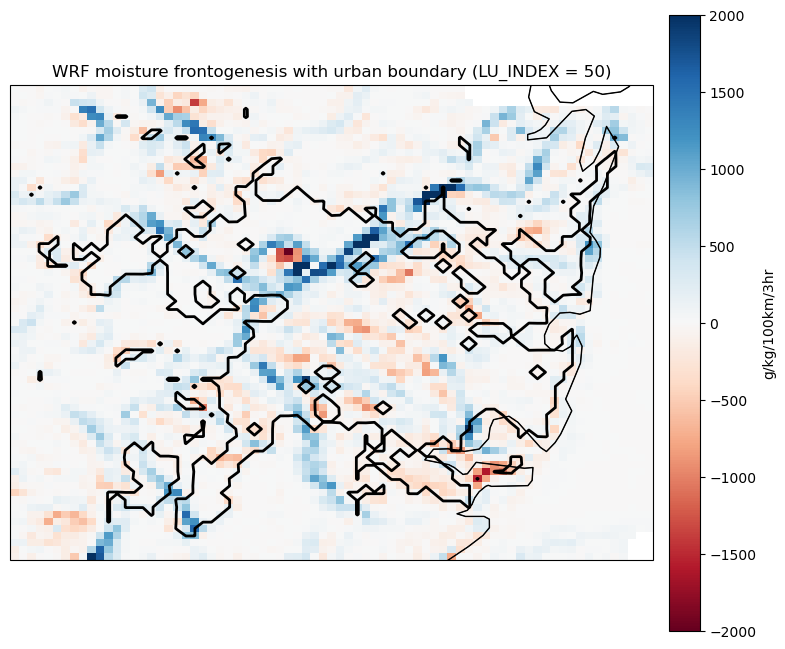

In [131]:
field_name = 'F' if 'F' in frontogenesis_ds else list(frontogenesis_ds.data_vars)[0]
front = frontogenesis_ds[field_name]

# Prepare 2D lon/lat for plotting
lon2d, lat2d = np.meshgrid(lon_reg, lat_reg)

fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})

vmin_global = -2000
vmax_global = 2000

# Plot frontogenesis field (full grid)
im = ax.pcolormesh(lon2d, lat2d, front, cmap='RdBu', shading='auto', transform=ccrs.PlateCarree(), vmin=vmin_global, vmax=vmax_global)
cb = plt.colorbar(im, ax=ax, orientation='vertical', pad=0.02)
cb.set_label(str(front.attrs.get('units', '')))

# Overlay coastlines
ax.coastlines(resolution='10m')
ax.add_feature(cfeature.NaturalEarthFeature('physical', 'land', '10m', facecolor='none', edgecolor='k', linewidth=0.5))

# Draw urban boundary (LU_INDEX = 50)
ax.contour(lon2d, lat2d, lu_reg, levels=[50], colors='black', linewidths=2, transform=ccrs.PlateCarree())

ax.set_title('WRF moisture frontogenesis with urban boundary (LU_INDEX = 50)')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

if save_figure:
    fig_path = out_dir / 'wrf_moisture_frontogenesis_with_winds_lu_gt_50.png'
    plt.savefig(fig_path, dpi=200, bbox_inches='tight')
    print('Saved figure to', fig_path)

plt.show()

## Multi-experiment comparison

Process all three experiments and create a 3-subplot figure with unified colorbar range.


In [133]:
# Define the three experiments in the desired subplot order: LCZ, WSF-MB, Geoscape
experiments = {
    'LCZ': Path('17Jan1500/LCZ/wrfout_d02_2017-01-17_05_00_00'),
    'WSF-MB': Path('17Jan1500/WSF-MB/wrfout_d02_2017-01-17_05_00_00'),
    'Geoscape': Path('17Jan1500/Geoscape/wrfout_d02_2017-01-17_05_00_00')
}

# Process each experiment and store results
frontogenesis_results = {}
lu_reg_results = {}
regrid_params = {}

for exp_name, wrf_path in experiments.items():
    print(f'\n===== Processing {exp_name} =====')
    
    # Load the WRF file
    ds_exp = xr.open_dataset(wrf_path)
    
    # Get lat/lon coordinates
    lat2d_exp = first_time_slice(ds_exp[lat_name]).squeeze()
    lon2d_exp = first_time_slice(ds_exp[lon_name]).squeeze()
    
    # Subset to the analysis box
    mask_exp = (lat2d_exp >= lat_min) & (lat2d_exp <= lat_max) & (lon2d_exp >= lon_min) & (lon2d_exp <= lon_max)
    ds_box_exp = ds_exp.where(mask_exp, drop=True)
    
    # Extract and compute specific humidity
    q2_exp = ds_box_exp['Q2']
    q_specific_exp = q2_exp / (1.0 + q2_exp)
    u_box_exp = ds_box_exp['U10']
    v_box_exp = ds_box_exp['V10']
    lu_box_exp = ds_box_exp['LU_INDEX']
    lat_box_exp = first_time_slice(ds_box_exp[lat_name]).squeeze()
    lon_box_exp = first_time_slice(ds_box_exp[lon_name]).squeeze()
    
    # Regrid to regular lat/lon grid (use the same grid as before)
    # If this is the first experiment, compute the regular grid; otherwise reuse
    if exp_name == 'LCZ':
        # Compute grid parameters from first experiment
        lat_step_exp = estimate_step(lat_box_exp[:, 0].values)
        lon_step_exp = estimate_step(lon_box_exp[0, :].values)
        
        if not np.isfinite(lat_step_exp) or lat_step_exp <= 0:
            lat_step_exp = 0.01
        if not np.isfinite(lon_step_exp) or lon_step_exp <= 0:
            lon_step_exp = 0.01
        
        lat_reg_exp = np.arange(float(lat_box_exp.min()), float(lat_box_exp.max()) + lat_step_exp, lat_step_exp)
        lon_reg_exp = np.arange(float(lon_box_exp.min()), float(lon_box_exp.max()) + lon_step_exp, lon_step_exp)
        
        regrid_params['lat_reg'] = lat_reg_exp
        regrid_params['lon_reg'] = lon_reg_exp
    else:
        # Reuse grid from first experiment
        lat_reg_exp = regrid_params['lat_reg']
        lon_reg_exp = regrid_params['lon_reg']
    
    # Regrid fields
    q_reg_exp = regrid_to_regular_latlon(q_specific_exp, lat_box_exp, lon_box_exp, lat_reg_exp, lon_reg_exp)
    u_reg_exp = regrid_to_regular_latlon(u_box_exp, lat_box_exp, lon_box_exp, lat_reg_exp, lon_reg_exp)
    v_reg_exp = regrid_to_regular_latlon(v_box_exp, lat_box_exp, lon_box_exp, lat_reg_exp, lon_reg_exp)
    lu_reg_exp = regrid_to_regular_latlon(lu_box_exp, lat_box_exp, lon_box_exp, lat_reg_exp, lon_reg_exp, method='nearest')
    
    # Compute frontogenesis
    front_exp = sea_breeze_funcs.kinematic_frontogenesis(q_reg_exp, u_reg_exp, v_reg_exp)
    field_name_exp = 'F' if 'F' in front_exp else list(front_exp.data_vars)[0]
    front_data_exp = front_exp[field_name_exp]
    
    # Apply LU_INDEX > 50 mask
    front_masked_exp = front_data_exp.where(lu_reg_exp > 50)
    
    # Store results
    #frontogenesis_results[exp_name] = front_masked_exp
    frontogenesis_results[exp_name] = front_data_exp
    lu_reg_results[exp_name] = lu_reg_exp
    
    print(f'{exp_name} frontogenesis range: {float(front_data_exp.min()):.2f} to {float(front_data_exp.max()):.2f}')

print('\n===== All experiments processed =====')


===== Processing LCZ =====
LCZ frontogenesis range: -4636.87 to 7555.47

===== Processing WSF-MB =====
WSF-MB frontogenesis range: -2773.18 to 3163.38

===== Processing Geoscape =====
Geoscape frontogenesis range: -2015.13 to 5187.25

===== All experiments processed =====


## Create 3-subplot comparison figure

Plot all three experiments side-by-side with a unified colorbar range.


Unified colorbar range: -2000.00 to 2000.00


C:\Users\z5493395\AppData\Local\Temp\ipykernel_36780\4106647427.py:62: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.06, 0.05, 0.92, 1.04])


Saved 3-experiment comparison figure to wrf_sea_breeze_output\wrf_moisture_frontogenesis_3experiments_comparison.png


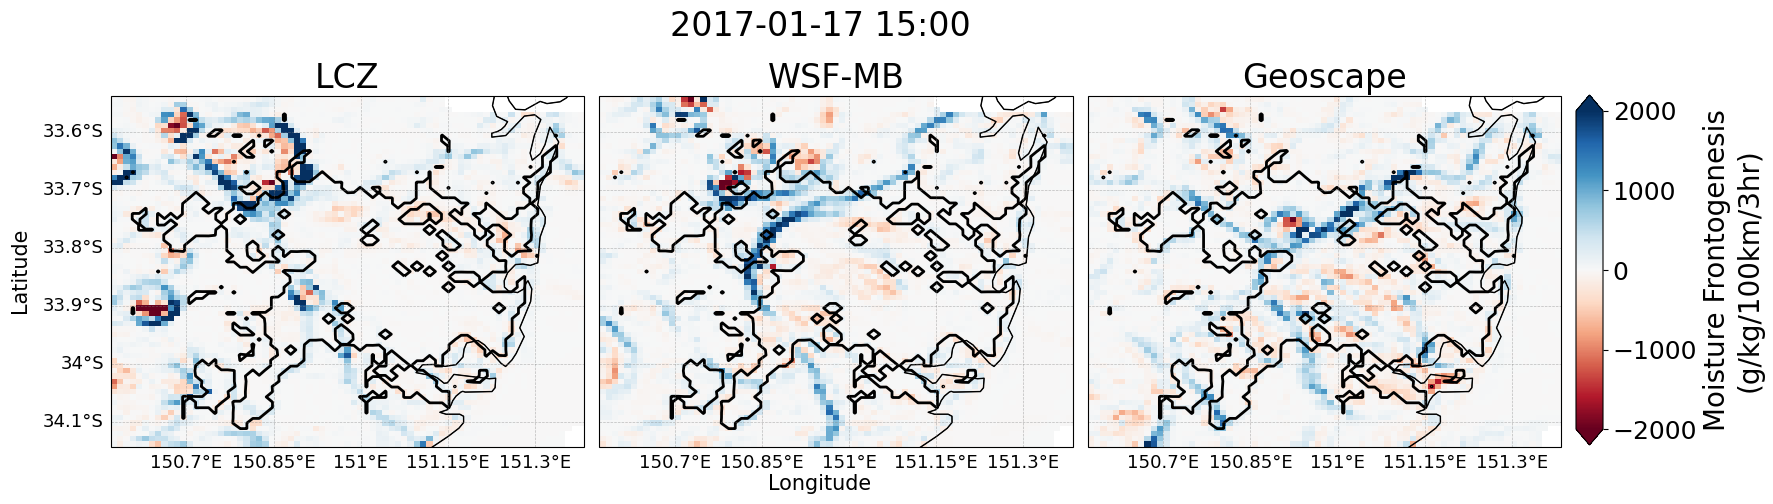

In [160]:
# Determine unified colorbar range across all three experiments
all_values = []
for front_field in frontogenesis_results.values():
    all_values.append(float(front_field.min()))
    all_values.append(float(front_field.max()))

all_values = np.array([v for v in all_values if np.isfinite(v)])
vmin_global = -2000
vmax_global = 2000

print(f'Unified colorbar range: {vmin_global:.2f} to {vmax_global:.2f}')

# Create 1x3 subplot figure
lat_reg = regrid_params['lat_reg']
lon_reg = regrid_params['lon_reg']
lon2d_multi, lat2d_multi = np.meshgrid(lon_reg, lat_reg)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), subplot_kw={'projection': ccrs.PlateCarree()})

# Plot each experiment in its respective subplot
for idx, (exp_name, ax) in enumerate(zip(['LCZ', 'WSF-MB', 'Geoscape'], axes)):
    front_exp_data = frontogenesis_results[exp_name]
    lu_reg_exp = lu_reg_results[exp_name]

    # Plot frontogenesis field (full grid) with unified colorbar range
    im = ax.pcolormesh(lon2d_multi, lat2d_multi, front_exp_data, cmap='RdBu', shading='auto', 
                        transform=ccrs.PlateCarree(), vmin=vmin_global, vmax=vmax_global)

    # Overlay coastlines
    ax.coastlines(resolution='10m')
    ax.add_feature(cfeature.NaturalEarthFeature('physical', 'land', '10m', facecolor='none', edgecolor='k', linewidth=0.5))

    # Draw urban boundary (LU_INDEX = 50)
    ax.contour(lon2d_multi, lat2d_multi, lu_reg_exp, levels=[50], colors='black', linewidths=2, transform=ccrs.PlateCarree())

    # Add lat/lon gridlines with labels
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
    gl.xlabel_style = {'size': 13}
    gl.ylabel_style = {'size': 13}
    gl.top_labels = False
    gl.right_labels = False
    
    # Only show y-labels (Latitude) on the left subplot
    if idx != 0:
        gl.left_labels = False
    
    ax.set_title(f'{exp_name}', fontsize=24)

# Add figure-level axis labels for Latitude and Longitude
fig.text(0.05, 0.5, 'Latitude', va='center', fontsize=15, rotation='vertical') #fontweight='bold',
fig.text(0.5, 0.06, 'Longitude', ha='center', fontsize=15) #, fontweight='bold'

# Add a single colorbar for all subplots
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax, orientation='vertical', extend='both')
cbar.set_label('Moisture Frontogenesis\n(g/kg/100km/3hr)', fontsize=20)
cbar.ax.tick_params(labelsize=18)

fig.suptitle('2017-01-17 15:00', 
             fontsize=24, y=1.02)

plt.tight_layout(rect=[0.06, 0.05, 0.92, 1.04])

if save_figure:
    fig_path_multi = out_dir / 'wrf_moisture_frontogenesis_3experiments_comparison.png'
    plt.savefig(fig_path_multi, dpi=200, bbox_inches='tight')
    print('Saved 3-experiment comparison figure to', fig_path_multi)

plt.savefig("seabreezeFrontogenesis.png", dpi=300)
plt.show()
plt.close()  # Close to free memory